# Grocery Stores
Supermarkets provide necessities for people in the neighborhood, improving the quality and convenience of people living within the vicinity of one. We will be using [this data from the Western Pennsylvania Regional Data Center](https://data.wprdc.org/dataset/allegheny-county-supermarkets-convenience-stores) ranking each neighborhood based on the number of grocery stores and supermarket within a given region. The amount of grocery stores in a neighborhood shows us how **accessible** they are to the community and how **diverse** the options truly are for people living in the region.

## Data Omitted
This data set obtained from the Western Pennsylvania Regional Data Center has had certain data points omitted, as shown by the following table:</p>

|      Data Point      |            Reason           |
|        :----         |            :----            |
|All Convenience Stores|To focus more on Supermarkets|
|      Client ID       |     Useless Info to Us      |
|     Legal Name       |     Useless Info to Us      |
|     Start Date       |     Useless Info to Us      |
|      Latitude        |     Useless Info to Us      |
|      Longitude       |     Useless Info to Us      |
|      Accuracy        |     Useless Info to Us      |

We promise you that the data included has not been altered apart from deleting the before-mentioned columns and rows.

On the data set obtained, we only have access to the ZIP codes and not the neighborhoods themselves. This is close enough, however, considering we were still able to reach our conclusion on which neighborhood has the most grocery stores.


In [44]:
import pandas as pd #Import Pandas Library for CSV Reading

df = pd.read_csv("Supermarkets.csv") #Store CSV into Variable
target_column = "Zip" #Set the target column to sort (ZIP Code)

df['Frequency'] = df.groupby(target_column)[target_column].transform('count') # Make temporary column counting the frequency of each ZIP Code
df_sorted = df.sort_values(by=['Frequency', target_column], ascending=[False, True]) # Sort values based off of the temporary frequency column
df_sorted = df_sorted.drop(columns=['Frequency']) # Discard temporary frequency column

df_sorted.head(30) # Print first 30 lines of the CSV

,Name,Street #,Street Name,Zip
7,Aldi #93,7221.0,Mcknight Rd,15237
22,Kuhn's Market,4801.0,Mcknight Rd,15237
29,Giant Eagle #0052,132.0,Ben Avon Heights Rd,15237
41,Giant Eagle #45,9805.0,Mcknight Rd,15237
48,Giant Eagle #67,8080.0,Mcknight Rd,15237
69,Shop 'n Save - Pines Plaza,1130.0,Perry Hi,15237
88,Sam's Club #6678,289.0,Mt Nebo Pointe Dr,15237
102,Trader Joe's #624,9020.0,Covenant Av,15237
131,Oriental Market,4768.0,Mcknight Rd,15237
149,Aldi #69,8000.0,Mcknight Rd,15237


## The 15237 Problem
Our most frequent ZIP Code is *15237* running at a total of *10 stores*, but that ZIP Code has multiple neighborhoods in one, including parts of Ross Township, McCandless Township, Ohio Township, and others. Technichally, this would be giving the 15237 ZIP Code an unfair advantage, so we will be removing the Ben Avon Heights Giant Eagle in Ohio Township, the McIntyre Square Giant Eagle (since legally it's apart of McCandless), the Mt. Nebo Sam's Club, and both the McCandless Trader Joe's and Giant Eagle. This will only leave 5 grocery stores total for Ross Township alone, the Ohio Township area has 2, and McCandless has 3. Regardless, that puts all four neighborhoods below the second most frequent data point.

## The 15205 Problem
Similar to 15237, *15205* also encompasses several neighborhoods including Robinson and Crafton, but this time, the two neighborhoods are separated by smaller ones in between. For the sake of accuracy, we will be splitting the grocery stores of Robinson and Crafton as well. Crafton will have the Giant Eagle in Crafton, the Giant Eagle on Noblestown Road, and the Save A Lot Crafton setting it at a total of 2 stores, whereas Robinson has the flagship Giant Eagle Market District store, GFS, and Costco.

## Ranking The Top 5

<Axes: ylabel='Zip'>

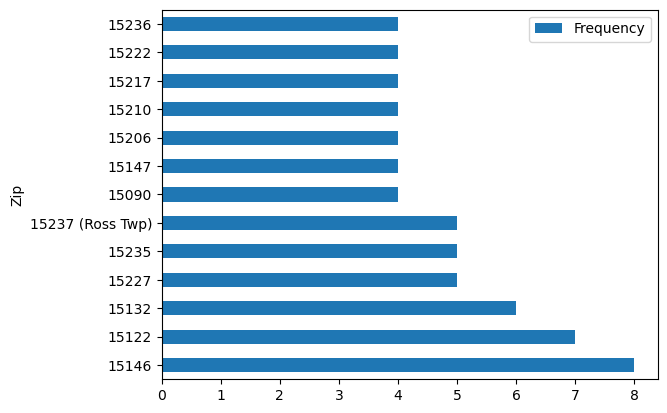

In [42]:
import pandas as pd #Import Pandas Library for CSV Reading

df = pd.read_csv("Supermarkets.csv") #Store CSV into Variable
target_column = "Zip" #Set the target column to sort (ZIP Code)

#Fix the 15237 Problem
df['Zip'] = df['Zip'].astype('string') #Set ZIP Type to String

#Manually sets ZIP Codes to display neighborhood.
df.at[48, 'Zip'] = '15237 (McCandless)' 
df.at[41, 'Zip'] = '15237 (McCandless)'
df.at[102, 'Zip'] = '15237 (McCandless)'
df.at[88, 'Zip'] = '15237 (Ohio Twp)'
df.at[29, 'Zip'] = '15237 (Ohio Twp)'
df.at[7, 'Zip'] = '15237 (Ross Twp)'
df.at[22, 'Zip'] = '15237 (Ross Twp)'
df.at[69, 'Zip'] = '15237 (Ross Twp)'
df.at[149, 'Zip'] = '15237 (Ross Twp)'
df.at[131, 'Zip'] = '15237 (Ross Twp)'
df.at[131, 'Zip'] = '15237 (Ross Twp)'

#Do the same for the 15205 Problem
df.at[83, 'Zip'] = '15205 (Crafton)'
df.at[144, 'Zip'] = '15205 (Crafton)'
df.at[74, 'Zip'] = '15205 (Crafton)'
df.at[147, 'Zip'] = '15205 (Robinson)'
df.at[42, 'Zip'] = '15205 (Robinson)'
df.at[14, 'Zip'] = '15205 (Robinson)'

df['Frequency'] = df.groupby(target_column)[target_column].transform('count') # Make temporary column counting the frequency of each ZIP Code
df = df.drop_duplicates(subset = ['Zip']);
df_sorted = df.sort_values(by=['Frequency', target_column], ascending=[False, True]) # Sort values based off of the temporary frequency column
df_sorted = df_sorted.drop(columns=['Name', 'Street #', 'Street Name']) # Discard temporary frequency column
df_sorted = df_sorted.head(13)
df_sorted.plot.barh(x='Zip', y='Frequency')

Coming in first is the zip code *15146*, which indeed encompasses the entirety of **Monroeville, PA** with **8 total grocery stores**. Not far behind, *West Mifflin, PA (15122)* takes second place with *7 total grocery stores*,  with *McKeesport (15132)* in third right behind with 6 grocery stores. Struggling for fourth place are Downtown Pittsburgh (15277), Penn Hills (15235), and Ross Township (partially 15237). Last but not least, lagging behind in fifth are Wexford, Verona, Highland Park, Mount Oliver and its surrounding neighborhoods, Squirrel Hil, the Strip District, and Whitehall.


|      Neighborhood    |    ZIP Code   | Number of Stores |
|        :----         |     :----     |       :----      |  
|1.    Monroeville     |     15146     |         8        |
|2.    West Mifflin    |     15122     |         7        |
|3.    McKeesport      |     15132     |         6        |
|4. Downtown Pittsburgh|     15277     |         5        |
|4.    Penn Hills      |     15235     |         5        |
|4.    Ross Township   | Part of 15237 |         5        |
|5.      Wexford       |     15090     |         4        |
|5.      Verona        |     15147     |         4        |
|5.    Highland Park   |     15206     |         4        |
|5.   Mount Oliver     |     15210     |         4        |
|5.  Squirrel Hill     |     15217     |         4        |
|5.   Strip District   |     15222     |         4        |
|5.    Whitehall       |     15236     |         4        |